In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import string
from collections import Counter

In [ ]:

## random Key generation
def random_key_gen(length):
    return np.random.randint(0,256,length)

##Character encoding to unicodes
def convert_to_unicode(unicode):
    unicode = [ord(i) for i in unicode]
    return unicode

##one-time pad encryption
def encryption(m,k):
    m_uni = np.array([ord(char) for char in m], dtype = 'int32')
    
    return m_uni ^ k

##one-time pad decryption
def decryption(c,k):
    
    return c ^ k

def convert_to_plaintext(m):
    return ''.join([chr(i) for i in m])

def convert_to_ciphertext(c):
    return ''.join([chr(i) for i in c])


##One-time pad algorithm
def one_time_pad(m):
    print("Message to be encrypted: ",m)
    print("Length of message: ",len(m))
    k = random_key_gen(len(m))
    print("Key: ",k)
    c = encryption(m,k)
    print("Ciphertext: ",c)
    print("Length of ciphertext: ",len(c))
    print("Plaintext: ",decryption(c,k))

    return c,k
    

def txt_file(f):
    with open(f,'r') as file:
             
     return file.read()
    
def test_OTP():
    m = txt_file('King_lear.txt')
    k = random_key_gen(len(m))
    
    c,k = one_time_pad(m)

    d = decryption(c,k)
    print("Decrypted message: ",convert_to_plaintext(d))
    print("Ciphertext: ",c)

    




In [ ]:
def get_pdf_plaintext(s):
    ##Probability distribution of the plaintext/message
    ##Ignoring non-printable characters and whitespaces
    s = ''.join(filter(lambda x: x in string.printable and not x.isspace(), s))

    freq = Counter(s)
    total = sum(freq.values())
    pdf_pt = {k: v/total for k,v in freq.items()}

    plt.figure(figsize=(14,6))
    plt.bar(freq.keys(), pdf_pt.values())
    plt.xlabel('Character')
    plt.ylabel('Probability')
    plt.title('PDF of plaintext')
    plt.grid(True)
    plt.xticks(rotation=90)
    plt.show()

    return pdf_pt

def get_pdf_ciphertext(c):
    ##Probability distribution of the ciphertext
    freq = Counter(c)
    total = sum(freq.values())
    pdf_ct = {k: v/total for k,v in freq.items()}

    plt.figure(figsize=(14,6))
    plt.bar(freq.keys(), pdf_ct.values())
    plt.xlim(0,256)
    plt.xlabel('Character')
    plt.ylabel('Probability')
    plt.title('PDF of ciphertext')
    plt.grid(True)
    plt.xticks(rotation=90)
    plt.show()

    return pdf_ct


    

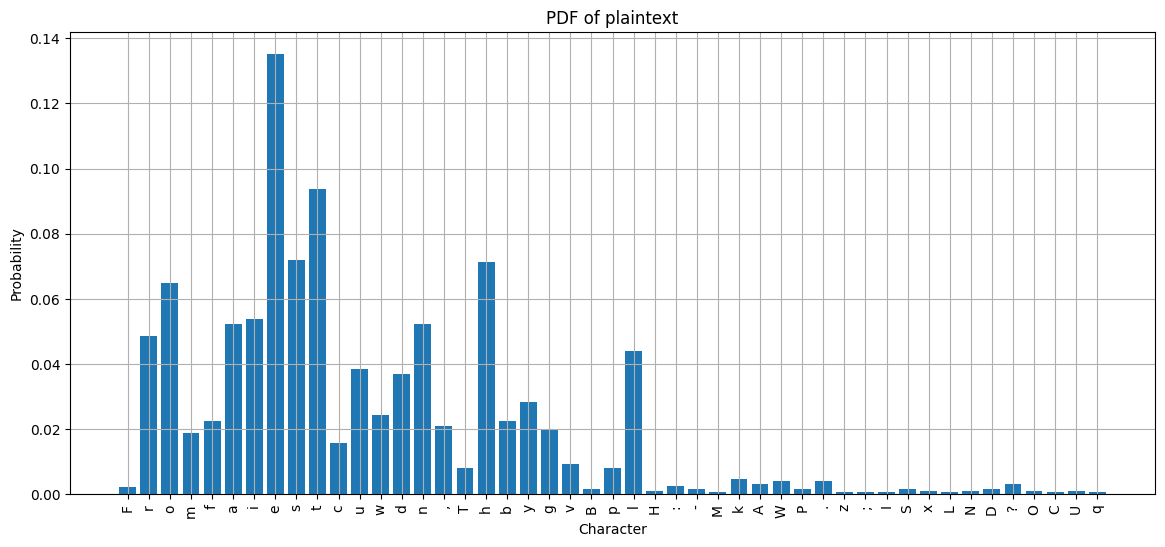

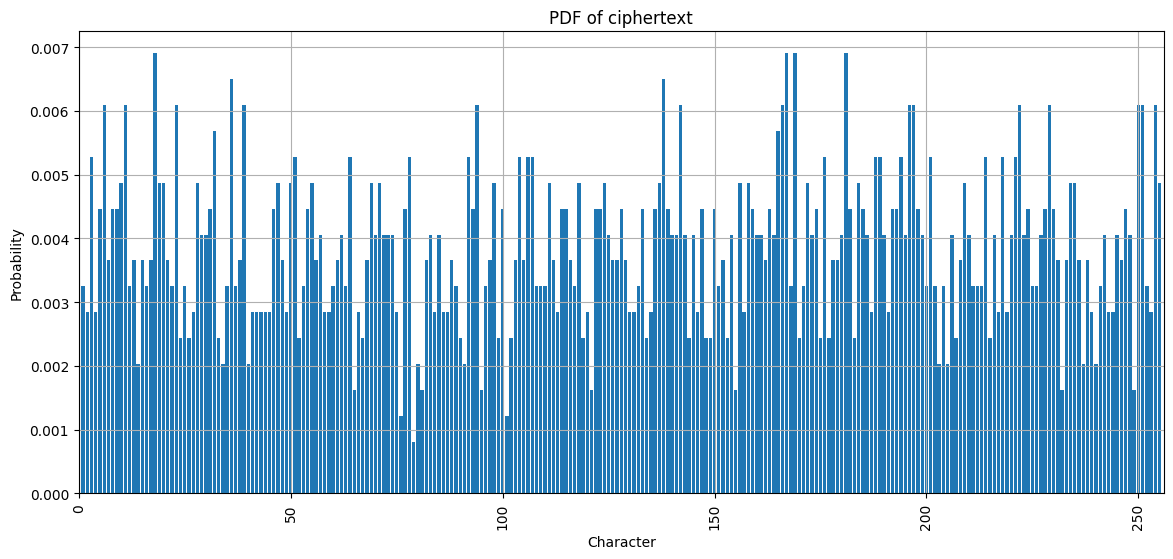

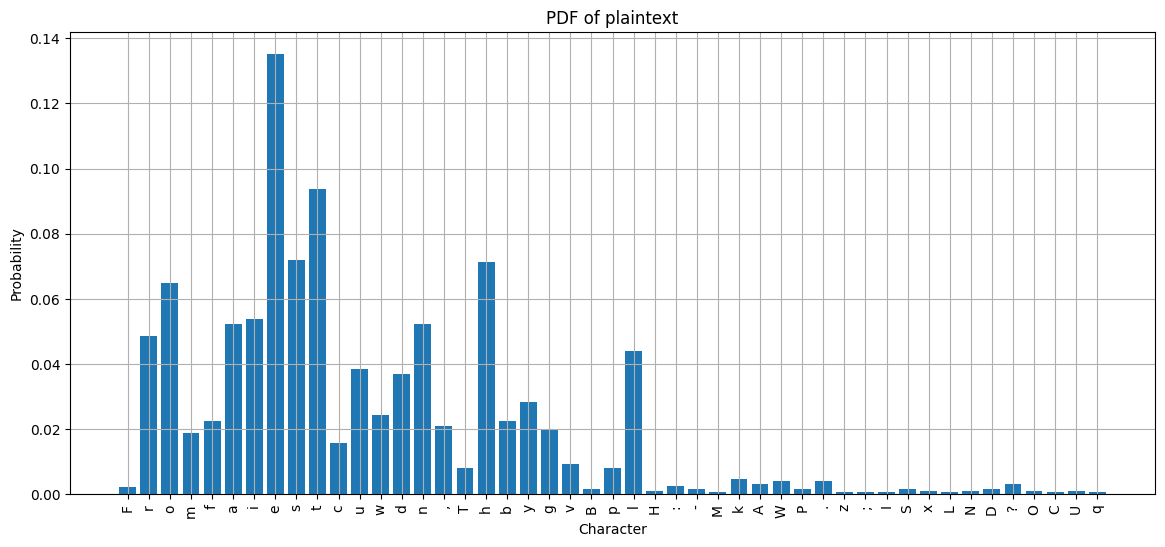

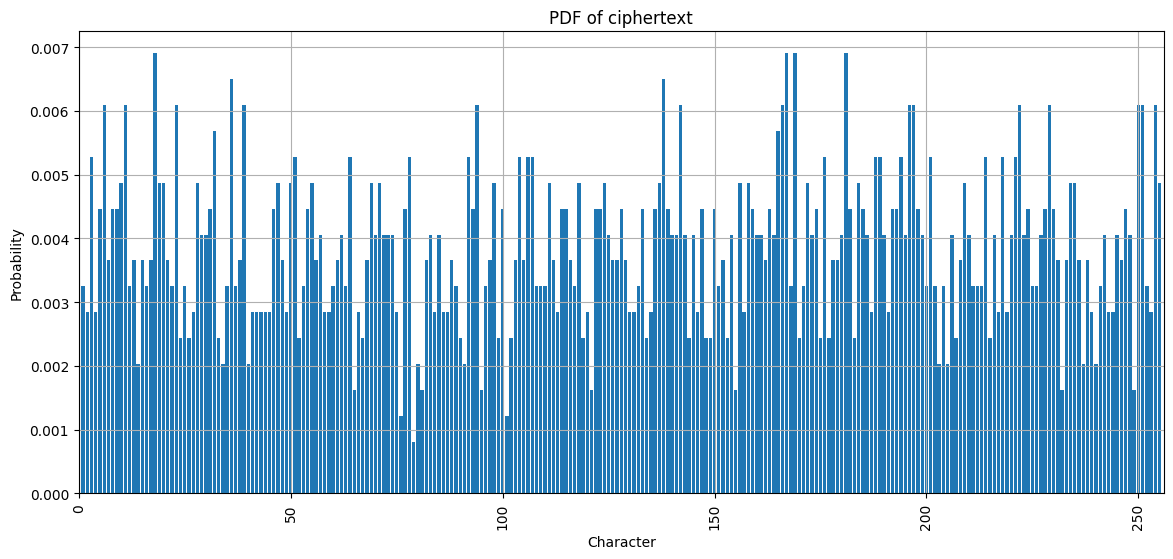

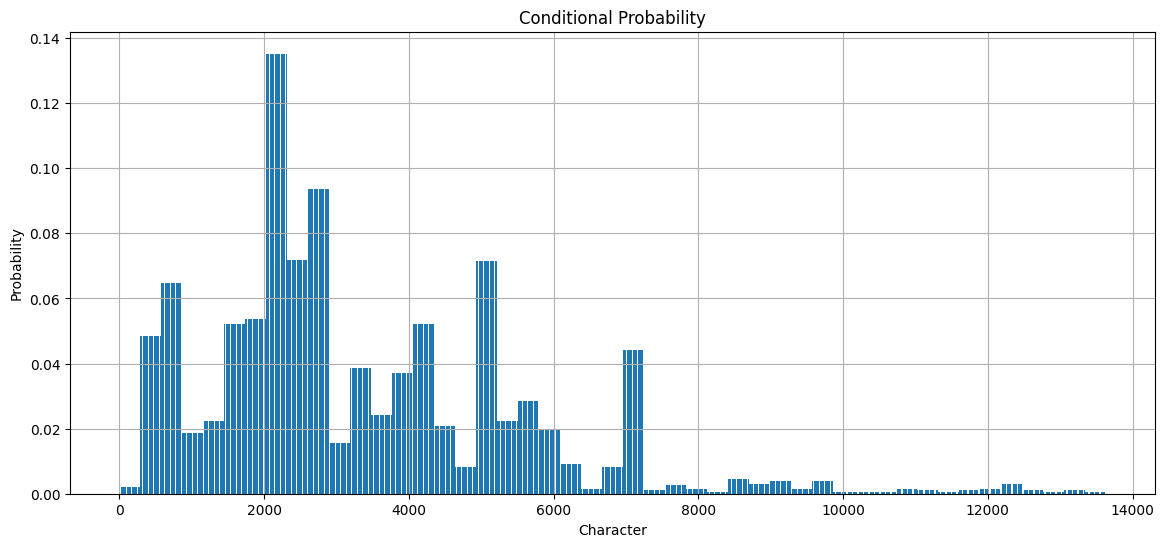

Entropy of message: 4.424 bits
Entropy of ciphertext: 7.994 bits
Conditional Entropy of message conditioned on cipher: 4.424 bits


In [ ]:

def joint_pdf(p_m,p_c):
    ##Joint Probability distribution of the plaintext and ciphertext P(M,C)
    pdf_joint = {}
    for m_char in p_m:
        for c_char in p_c:
            pdf_joint[(m_char, c_char)] = p_m[m_char] * p_c[c_char]

    return pdf_joint
    
    
def conditional_probability(pdf_joint, p_c):
    ##Conditional probability P(M|C)
    cond_prob = {}
    for (m_char, c_char), joint_p in pdf_joint.items():
        if p_c[c_char] != 0:
            cond_prob[(m_char, c_char)] = joint_p / p_c[c_char] 
                      
    return cond_prob       

def get_conditional_probability(m,c):
    ##Plotting the conditional probability P(M|C)
    p_m = get_pdf_plaintext(m)
    p_c = get_pdf_ciphertext(c)
    pdf_joint = joint_pdf(p_m,p_c)
    cond_prob = conditional_probability(pdf_joint, p_c)
    cond_prob_val = [prob for _, prob in cond_prob.items()]
    # cond_prob_val = [cond_prob.get(chr(i), 0) for i in range(256)]
    plt.figure(figsize=(14,6))
    plt.bar(range(len(cond_prob_val)), cond_prob_val)
    # plt.bar(range(256), cond_prob_val)
    plt.xlabel('Character')
    plt.ylabel('Probability')
    plt.title('Conditional Probability')
    plt.grid(True)
    plt.show()

def entropy(p):
    return round(-sum(prob*math.log2(prob) for prob in p.values() if prob != 0), 3)
    

def conditional_entropy(pdf_joint, cond_prob):
    return round(-sum(pdf_joint[(m_char, c_char)]*math.log2(cond_prob[(m_char, c_char)]) for (m_char, c_char) in pdf_joint.keys() if cond_prob[(m_char, c_char)] != 0), 3)

   

def main():
    # Read the text file
    m = txt_file('King_lear.txt')
    # Generate a random key
    k = random_key_gen(len(m))
    # Encrypt the message
    c = encryption(m,k)
    # c,k = one_time_pad(m)
    
    # Get the PDF of plaintext
    p_m = get_pdf_plaintext(m)
    # # Get the PDF of ciphertext
    p_c = get_pdf_ciphertext(c)
    pdf_joint = joint_pdf(p_m,p_c)

    p_m_cond_c = conditional_probability(pdf_joint, p_c)


    # Get the conditional probability
    get_conditional_probability(m,c)

    ##entropy
    print(f"Entropy of message: {entropy(p_m)} bits" )
    print(f"Entropy of ciphertext: {entropy(p_c)} bits")
    print(f"Conditional Entropy of message conditioned on cipher: {conditional_entropy(pdf_joint, p_m_cond_c)} bits")
       

#    print()

main()



